# Bouquet: reconstruction example (g-file + IDA-layout profile fit)

**Bouquet** propagates input uncertainty into Grad-Shafranov equilibria: it
perturbs the measured inputs within their error bars and re-solves each draw
with **TokaMaker** (OpenFUSION Toolkit), producing a *bouquet* of equilibria
spanning what the data allows.

This notebook starts from an **EFIT-style g-file** plus an **IDA-layout
kinetic-profile fit** (`.cdf`), reconstructs a self-consistent baseline with
the unified engine, and generates a bouquet. Everything runs on the synthetic
fixtures the test suite is built on (`tests/data`, see its `README.md` and
`FIXTURE_SPEC.md`), so it runs end to end with no external data:

| case | g-file | profile fit | what it is |
|---|---|---|---|
| H-mode (main) | `g_synthetic.geqdsk` | `diiid_profs_synthetic.cdf` | pedestal-forming H-mode, lower single null, 1.0 MA, B0 -2 T |
| L-mode (second case) | `g_synthetic_lmode.geqdsk` | `ida_synthetic_lmode.cdf` | sawtoothing L-mode (q0 0.8), upper single null, 1.3 MA |

The kinetic σ come from the fit file's own `*_err` envelopes (radial
templates; `FIXTURE_SPEC.md` section 7). Each g-file carries the pressure
its profile fit gives on this route, e (n_e T_e + n_i T_i) with n_i from
Z_eff: an IDA-layout fit has no fast-ion channel, so the H-mode g-file is
its thermal-only equilibrium (`tests/data/README.md`).

**Layout:** (1) the inputs, (2) a minimal run, (3) the outputs, (4) the
in-spec filter, (5) a second case on the same solver, (6) working with the
archive, (7) error bars.

**p-file route.** `from_geqdsk(g, profiles=...)` also takes an Osborne
p-file (the reader dispatches on the file type). `tests/data` carries one
for the same 1.2 s slice: `g_synthetic_pfast.geqdsk` (the total pressure,
fast ions included) + `p_synthetic.peqdsk`, whose `pb` block is the beam
pressure [kPa]; pass it as `fixed_components.p_fast` (x 1e3, Pa, on the
p-file's psinorm). This notebook does not run that variant.

> **Prereq:** the OpenFUSION Toolkit importable (`OFT_PYTHONPATH=/path/to/OpenFUSIONToolkit/build_release/python`).
> **Runtime:** each case draws until 24 draws are in spec, roughly 40-50 solves of 1-2 min each on one core.


In [1]:
import os
import bouquet as bq
bq.add_oft_to_path()          # OFT_PYTHONPATH, known install locations or a sibling checkout
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 72})

DATA = os.path.abspath(os.path.join("..", "..", "tests", "data"))   # the synthetic fixtures
MESH = bq.find_mesh()          # the TokaMaker mesh (BOUQUET_MESH, else the one shipped in examples/)
# until-N: keep drawing until this many draws are IN SPEC (the coil test + the boundary cut).
# 24 is the default for every example; use 30 for 5/95 bands, 50 for paper-quality widths.
N_INSPEC = int(os.environ.get("BOUQUET_EXAMPLE_N_INSPEC", 24))   # (the variable is a smoke-test override)

GFILE   = os.path.join(DATA, "g_synthetic.geqdsk")          # H-mode equilibrium (shape + current)
IDA     = os.path.join(DATA, "diiid_profs_synthetic.cdf")   # its kinetic-profile fit (n, T, Z_eff + sigmas)
GFILE_L = os.path.join(DATA, "g_synthetic_lmode.geqdsk")    # the L-mode pair
IDA_L   = os.path.join(DATA, "ida_synthetic_lmode.cdf")
print("bouquet", bq.__version__, "| until-N target:", N_INSPEC)

bouquet 1.3.1 | until-N target: 24


## 1. The inputs

The **g-file** gives the equilibrium (LCFS shape, pressure, q, current, P',
FF'); the **profile fit** gives n_e, T_e, T_i and Z_eff with their 1σ
envelopes, which are the uncertainties the draws sample.


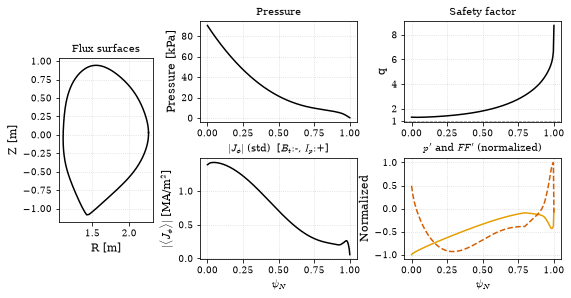

[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst -0.0% at psi_N=0.63  (report-only; see Callahan 2019 JINST 14 C10002)


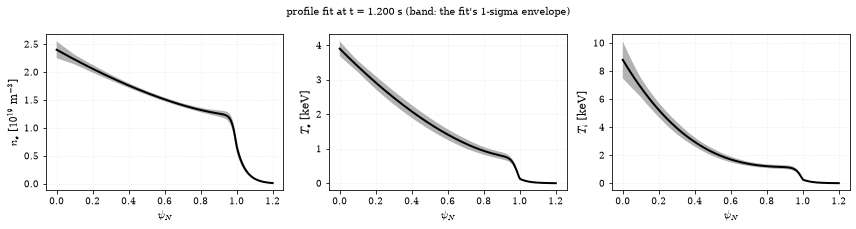

In [2]:
bq.plot_geqdsk_bouquet(GFILE); plt.show()

ida = bq.read_ida(IDA)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, (y, s, lab, sc) in zip(ax, [(ida.ne, ida.sigma_ne, r"$n_e$ [$10^{19}$ m$^{-3}$]", 1e19),
                                   (ida.te, ida.sigma_te, r"$T_e$ [keV]", 1e3),
                                   (ida.ti, ida.sigma_ti, r"$T_i$ [keV]", 1e3)]):
    a.plot(ida.psi_N, y / sc, "k"); a.fill_between(ida.psi_N, (y - s) / sc, (y + s) / sc, alpha=0.3)
    a.set_xlabel(r"$\psi_N$"); a.set_ylabel(lab); a.grid(alpha=0.3)
fig.suptitle(f"profile fit at t = {ida.time:.3f} s (band: the fit's 1-sigma envelope)", fontsize=10)
plt.tight_layout(); plt.show()

## 2. A minimal run

Create the driver, set the **until-N target** and a seed, then reconstruct and
generate. The defaults are the validated ones: the unified reconstruction
engine, the self-consistent Redl bootstrap in the reconstruction and in every
draw, the kinetic σ from the fit file, `jphi_scalar_sigma` on the current
profile, and the in-spec rule of the magnetics (the coil χ² test and the
boundary cut; the l_i band is opt-in).

`n_inspec_target` makes the run keep drawing until that many draws are in
spec (`n_draws` is only the initial allocation), so ensembles are comparable
in size whatever the yield.


In [3]:
HEADER = "synthetic_Hmode"        # output -> synthetic_Hmode.h5
run = bq.Bouquet.from_geqdsk(GFILE, profiles=IDA, mesh=MESH, n_draws=N_INSPEC,
                             header=HEADER, impurity_Z=6.0)   # carbon; set it for your machine
run.generation.n_inspec_target = N_INSPEC     # until-N: draw until N are in spec
run.generation.seed = 20261015                # reproducible perturbations
print("engine:", run.generation.reconstruction_engine, "| check_bistability:",
      run.generation.check_bistability, "(None = on under the unified engine)")

engine: unified | check_bistability: None (None = on under the unified engine)


`reconstruct()` builds the baseline from the g-file and the profile fit and
prints a **fidelity report** (TokaMaker against the input). Under the unified
engine it also runs the **bistability check** (on by default since 1.4.0): one
extra solve of the same inputs from a cold start, compared with the delivered
state at the σ=0 gates. A miss stamps the baseline `bistable=True` and warns;
nothing is refused.


In [4]:
run.reconstruct();

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        
Development branch:  fix/jphi-update-ravgs-and-nonfinite-abort
Revision id:         7da4f18

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    1

Linear Algebra backend: native

#----------------------------------------------


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =    8910
    # of edges   =   26567
    # of cells   =   17658
    # of boundary points =     160
    # of boundary edges  =     160
    # of boundary cells  =     160
  Resolution statistics:
    hmin =  8.702E-04
    hrms =  4.833E-02
    hmax =  1.540E-01
  Surface grounded at vertex    1733


**** Creating Lagrange FE space
  Order  =    3
  Minlev = 

 Inverting real matrix
   Time =    8.4416409999999997E-003


[engine] bistability check: single (dl_i -4.46e-06, dq0 -1.10e-05; one extra solve)




=== Reconstruction — g_synthetic.geqdsk ====================== PASS ✅
  converged    yes
  Ip           1.000 MA      (input 1.000 MA, -0.00%)
  l_i(3)       0.835         (input 0.835, +0.00%)
    l_i(1)x    1.062         (input 1.071, -0.80%)
  q0@0.02      1.41          (input 1.31, +7.54%)
                             (g-file axis q(0) 1.32, +6.87% -- a different radius)
  q95          4.78          (input 4.85, -1.40%)
  beta_N       0.80          (input 1.68, -52.58%)
  beta_p       0.44          (input 0.92, -52.07%)
  kappa        1.768         (input 1.754, +0.80%)
  delta        0.331         (input 0.331, +0.26%)
  j_sep(.99)   0.259 MA/m²   (input 0.244 MA/m², +5.99%)
  W_MHD        0.283 MJ      (input 0.596 MJ, -52.49%)
  p_sep        366 Pa (input edge 358.4 Pa; separatrix_pressure='offset', added back 366 Pa; edge_pprime_pin=True)
    p - p_sep  beta_N 0.772 (input 1.658, -53.43%)   W_MHD 0.2739 MJ (input 0.5869, -53.34%)
    full p     beta_N 0.798 (input 1.684, -52.

In [5]:
b = run.baseline.engine.get("bistability") or {}
print(f"bistability check: checked={b.get('checked')}  bistable={b.get('bistable')}  "
      f"outcome={b.get('outcome')}  extra solves={b.get('extra_solves')}")
for name, g in (b.get("gates") or {}).items():
    print(f"  {name:5s} = {g['value']:+.2e}  (bound {g['bound']:g}, {g['setting']})  passed={g['passed']}")

bistability check: checked=True  bistable=False  outcome=single  extra solves=1
  dl_i  = -4.46e-06  (bound 0.001, jbs_tol_li)  passed=True
  dq0   = -1.10e-05  (bound 0.002, jbs_tol_q0)  passed=True


Before spending compute on the draws, two checks: the **σ=0 identity**
(the draw route with every perturbation zero must reproduce the
reconstruction) and the input-vs-reconstruction overlay.


[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst -0.0% at psi_N=0.63  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA diiid_profs_synthetic.cdf (peak 1.512e+18)
  [sigma-source] sigma_te   <- IDA diiid_profs_synthetic.cdf (peak 214.5)
  [sigma-source] sigma_ni   <- IDA diiid_profs_synthetic.cdf (peak 1.391e+18)
  [sigma-source] sigma_ti   <- IDA diiid_profs_synthetic.cdf (peak 1320)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 1.393e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)
[boundary cut] LCFS rms <= 8.5 mm (device:DIII-D calibration: across-slice 90th percentile (8.34 mm) of the LCFS rms displacement under the magnetics' stated noise in a pre-registered boundary-UQ study, rounded to 8.5 mm; replaces the generic 5 mm; filtering.rms_max_mm overrides)


[draw-solves] 7 solves, none failed (maxits solver default)
[generate] 1 attempt(s): 1 archived, 0 rejected (not archived, not counted) -- by reason: none; axis branch: 0 of 1 archived engine draw(s) 'other' (axis > 0.01 x a from the reconstruction's; reported, never a filter)
[sigma0-check engine route] PASS: loop: request bit-identical, converged, r_j=2.65e-05 r_I=1.06e-06 dl_i=+2.76e-06; archived: r_j=2.65e-05 r_I=1.06e-06 dl_i=-5.77e-05 dq0=-5.46e-05 dq95=-7.67e-05 dflux_rel=+4.49e-05; coils/LCFS: coil_F_drift_pct=0.000784 (bound 1), coil_VSC_drift_pct=0.0196 (bound 1), boundary_rms_mm=0.433 (bound 8.5) (tol r_j 0.001, r_I 0.0001, l_i 0.001, q0 0.002)


sigma=0 identity passed: True


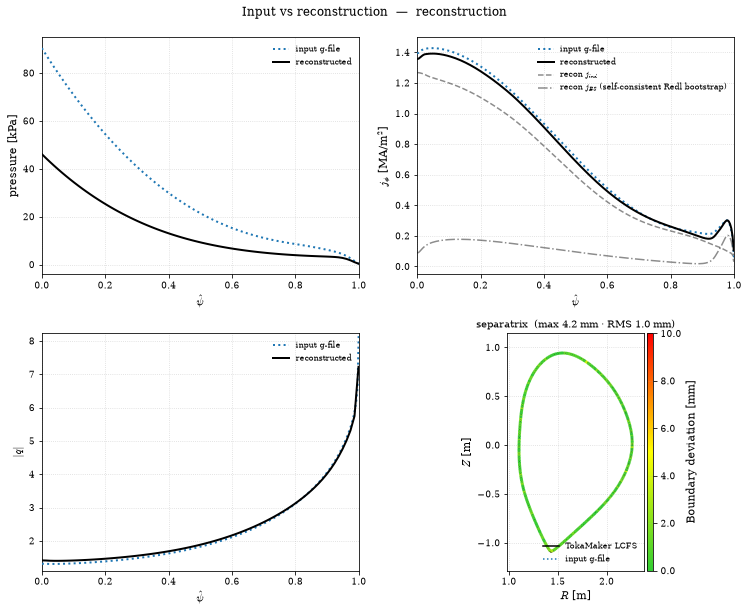

In [6]:
chk = run.verify_sigma0_consistency()
print("sigma=0 identity passed:", chk["passed"])
bq.plot_input_vs_recon(run); plt.show()

In [7]:
run.generate(); run.filter(); run.export();    # draw until N in spec, screen, write the in-spec file

[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst -0.0% at psi_N=0.63  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA diiid_profs_synthetic.cdf (peak 1.512e+18)
  [sigma-source] sigma_te   <- IDA diiid_profs_synthetic.cdf (peak 214.5)
  [sigma-source] sigma_ni   <- IDA diiid_profs_synthetic.cdf (peak 1.391e+18)
  [sigma-source] sigma_ti   <- IDA diiid_profs_synthetic.cdf (peak 1320)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 1.393e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)


[draw-solves] 4/559 solves failed (4 exceeded maxits solver default), 92 s; recovered 0; lost 4, draws [14, 18, 28, 41]: solve:1476 x4
[generate] 44 attempt(s): 44 archived, 0 rejected (not archived, not counted) -- by reason: none; axis branch: 25 of 44 archived engine draw(s) 'other' (axis > 0.01 x a from the reconstruction's; reported, never a filter)
[generate] 4 engine-draw GS solve(s) stopped at engine_draw_solve_maxits=100: homotopy rolled_back x4; per-solve records: Bouquet.engine_draw_cap_events
[until-N] target met: 24/24 in-spec draws in 44 attempts.


  coil chi2 filter: era undetermined (BouquetConfig.device is not set, so no era table applies yet) -> the device detected from the mesh uses its default band, which carries the TIGHTEST floor  [set filtering.coil_daq_era to state the era]


bouquet/filtering.py:1202: UserWarning: coil tolerance: no era given for device 'DIII-D', whose sigma floor is era-dependent (known eras: ['modern', 'pre2014']). Falling back to the default band, which carries the TIGHTEST floor -- an unknown era must not buy a looser tolerance. Set filtering.coil_daq_era explicitly (or supply an explicit pulse number on the source) to select the right one.
  sig, model = resolve_coil_sigma(baseline, sigma=sigma, device=device, era=era)


bouquet/run.py:8574: UserWarning: coil filter: acceptance chi2/nu <= 6.1 and max|z| <= 6.3 were calibrated over 18 coils but are being applied over 20. These are empirical quantiles, not dof-based bounds: max|z| is an order statistic whose quantile rises with the coil count, so the true false-rejection rate is ABOVE the nominal 5%. Thresholds are unchanged; recalibrate them over the judged coil set, or restrict the metric to the calibrated set, before relying on the quantile.
  coil_summary = filter_coil_chi2(



=== Bouquet — synthetic_Hmode ===================  24/44 in-spec (55%)
  draws         44 generated to deliver 24/24 requested in-spec (target met)
  coil spec     43/44 chi2/nu <= 6.1, |z| <= 6.3 [device q95, 20 coils]   (1 out-of-spec)
  boundary      RMS median 8.15 mm   max 20.17 mm
  in-spec rule  magnetics   (coil test + boundary cut; l_i, beta_p and Lambda reported, not filtered)


## 3. The outputs

- **`plot_traces`**: per-draw l_i, the LCFS deviation against the boundary cut,
  and the anchor-displacement heatmap;
- **`plot_bouquet(mode="j-phi")`**: the current-profile family (other modes:
  `kinetic`, `pressure`, `boundary`, `all`).

Filled markers are in-spec draws; open markers were excluded by the filter.


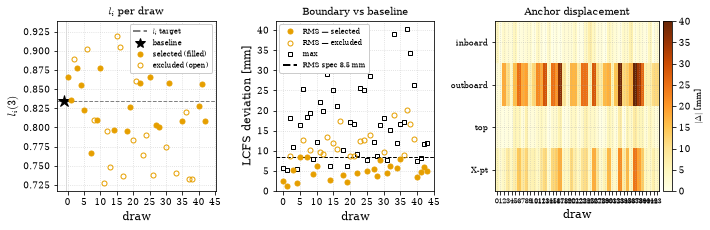

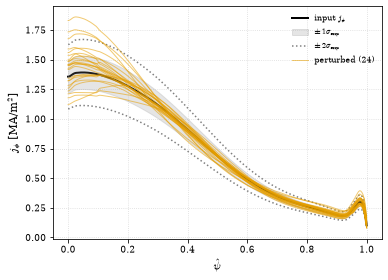

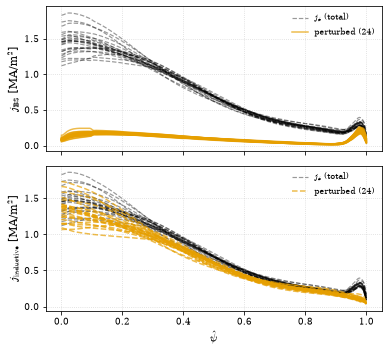

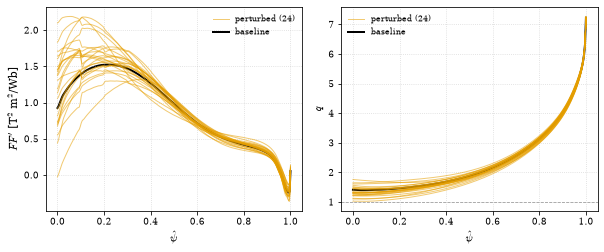

In [8]:
bq.plot_traces(HEADER + ".h5", scan_key=0, rms_max_mm=run.boundary_cut()[0]); plt.show()
bq.plot_bouquet(HEADER + ".h5", scan_key=0, mode="j-phi", selection="selected"); plt.show()

## 4. The in-spec filter

`run.filter()` already screened the draws: the **coil test** (a
measurement-referenced χ² of the coil currents against the device's coil
uncertainties) and the **boundary cut** (LCFS RMS deviation, the device's
calibrated threshold). `selected` is their AND. The flags are read back
here; a re-cut at a different boundary threshold is a what-if with
`apply=False`.


stored draws: 44   coil test pass: 43   boundary cut pass: 24   in spec: 24


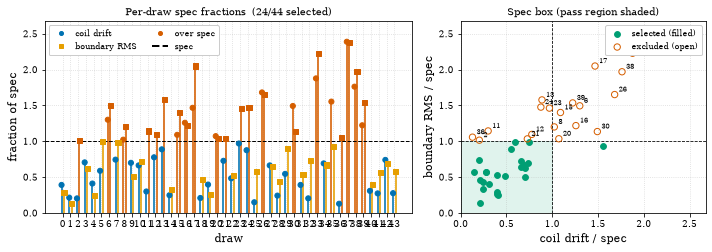

what-if at half the boundary cut (4.25 mm): 36/44 draws would fail


In [9]:
flags = bq.read_filter_flags(HEADER, scan_key=0)
n_coil = sum(f.get("passes_coil_filter", False) for f in flags.values())
n_bnd = sum(f.get("passes_boundary_filter", False) for f in flags.values())
sel = bq.select_indices(HEADER, scan_key=0, selection="selected")
print(f"stored draws: {len(flags)}   coil test pass: {n_coil}   boundary cut pass: {n_bnd}   in spec: {len(sel)}")
rms_cut = run.boundary_cut()[0]
bq.plot_spec_summary(HEADER, scan_key=0, rms_max_mm=rms_cut); plt.show()
bs, _ = bq.filter_boundaries(HEADER, rms_max_mm=0.5 * rms_cut, scan_key=0, apply=False, plot=False)
print(f"what-if at half the boundary cut ({0.5 * rms_cut:.2f} mm): "
      f"{sum(not d['passes'] for d in bs['draws'].values())}/{bs['n_total']} draws would fail")

## 5. A second case on the same solver: the L-mode pair

`set_case` points the driver at a new baseline and keeps the solver (the
OpenFUSION environment is one per process). The run settings carry over; the
σ come from the new fit file.


In [10]:
HEADER_L = "synthetic_Lmode"
src_l = bq.Bouquet.from_geqdsk(GFILE_L, profiles=IDA_L, mesh=MESH, impurity_Z=6.0).config.source
run.set_case(source=src_l, header=HEADER_L, scan_key=0)
run.reconstruct();
print("sigma=0 identity passed:", run.verify_sigma0_consistency()["passed"])
run.generate(); run.filter(); run.export();

[engine] bistability check: single (dl_i -1.70e-06, dq0 -7.73e-06; one extra solve)




=== Reconstruction — g_synthetic_lmode.geqdsk ================ PASS ✅
  converged    yes
  Ip           1.300 MA      (input 1.300 MA, -0.00%)
  l_i(3)       1.042         (input 1.042, -0.05%)
    l_i(1)x    1.307         (input 1.289, +1.42%)
  q0@0.02      0.81          (input 0.81, -0.28%)
                             (g-file axis q(0) 0.80, +0.86% -- a different radius)
  q95          3.84          (input 3.79, +1.23%)
  beta_N       0.79          (input 0.80, -1.14%)
  beta_p       0.35          (input 0.35, +0.64%)
  kappa        1.728         (input 1.708, +1.16%)
  delta        0.422         (input 0.406, +3.98%)
  j_sep(.99)   0.063 MA/m²   (input 0.004 MA/m², +1407.61%)
  W_MHD        0.383 MJ      (input 0.387 MJ, -0.82%)
  p_sep        591.5 Pa (input edge 592.9 Pa; separatrix_pressure='offset', added back 591.5 Pa; edge_pprime_pin=True)
    p - p_sep  beta_N 0.757 (input 0.766, -1.19%)   W_MHD 0.3671 MJ (input 0.3704, -0.87%)
    full p     beta_N 0.791 (input 0.800, -1

[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst +0.0% at psi_N=0.69  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA ida_synthetic_lmode.cdf  (peak 1.98e+18)
  [sigma-source] sigma_te   <- IDA ida_synthetic_lmode.cdf  (peak 145.8)
  [sigma-source] sigma_ni   <- IDA ida_synthetic_lmode.cdf  (peak 1.742e+18)
  [sigma-source] sigma_ti   <- IDA ida_synthetic_lmode.cdf  (peak 296)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 2.5e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)
[boundary cut] LCFS rms <= 8.5 mm (device:DIII-D calibration: across-slice 90th percentile (8.34 mm) of the LCFS rms displacement under the magnetics' stated noise in a pre-registered boundary-UQ study, rounded to 8.5 mm; replaces the generic 5 mm; filtering.rms_max_mm overrides)


[draw-solves] 7 solves, none failed (maxits solver default)
[generate] 1 attempt(s): 1 archived, 0 rejected (not archived, not counted) -- by reason: none; axis branch: 0 of 1 archived engine draw(s) 'other' (axis > 0.01 x a from the reconstruction's; reported, never a filter)
[sigma0-check engine route] PASS: loop: request bit-identical, converged, r_j=4.18e-05 r_I=3.57e-06 dl_i=-2.07e-05; archived: r_j=4.18e-05 r_I=3.58e-06 dl_i=-2.88e-05 dq0=-4.65e-05 dq95=-1.21e-04 dflux_rel=+2.97e-05; coils/LCFS: coil_F_drift_pct=0.000973 (bound 1), coil_VSC_drift_pct=0.0139 (bound 1), boundary_rms_mm=0.485 (bound 8.5) (tol r_j 0.001, r_I 0.0001, l_i 0.001, q0 0.002)


sigma=0 identity passed: True
[read_ida] Zeff(VB) vs 1+Z(Z-1)nC/ne (CER carbon), psi_N<=0.9: median +0.0%, worst +0.0% at psi_N=0.69  (report-only; see Callahan 2019 JINST 14 C10002)
  [sigma-source] sigma_ne   <- IDA ida_synthetic_lmode.cdf  (peak 1.98e+18)
  [sigma-source] sigma_te   <- IDA ida_synthetic_lmode.cdf  (peak 145.8)
  [sigma-source] sigma_ni   <- IDA ida_synthetic_lmode.cdf  (peak 1.742e+18)
  [sigma-source] sigma_ti   <- IDA ida_synthetic_lmode.cdf  (peak 296)
  [sigma-source] sigma_jphi <- scalar 0.1 x |j_phi|         (peak 2.5e+05)
[sigma] zeff envelope <- carbon-propagated (n_12C6_err)
  [sigma-source] ni per draw   <- derived from the drawn (ne, Z_eff)


[draw-solves] 2/404 solves failed (2 exceeded maxits solver default), 47 s; recovered 0; lost 2, draws [32, 33]: solve:1476 x2
[generate] 34 attempt(s): 33 archived, 1 rejected (not archived, not counted) -- by reason: homotopy_maxits=1; axis branch: 13 of 33 archived engine draw(s) 'other' (axis > 0.01 x a from the reconstruction's; reported, never a filter)
[generate] 2 engine-draw GS solve(s) stopped at engine_draw_solve_maxits=100: homotopy rejected x1, homotopy rolled_back x1; per-solve records: Bouquet.engine_draw_cap_events
[until-N] target met: 24/24 in-spec draws in 34 attempts.


  coil chi2 filter: era undetermined (BouquetConfig.device is not set, so no era table applies yet) -> the device detected from the mesh uses its default band, which carries the TIGHTEST floor  [set filtering.coil_daq_era to state the era]


bouquet/filtering.py:1202: UserWarning: coil tolerance: no era given for device 'DIII-D', whose sigma floor is era-dependent (known eras: ['modern', 'pre2014']). Falling back to the default band, which carries the TIGHTEST floor -- an unknown era must not buy a looser tolerance. Set filtering.coil_daq_era explicitly (or supply an explicit pulse number on the source) to select the right one.
  sig, model = resolve_coil_sigma(baseline, sigma=sigma, device=device, era=era)
bouquet/run.py:8574: UserWarning: coil filter: acceptance chi2/nu <= 6.1 and max|z| <= 6.3 were calibrated over 18 coils but are being applied over 20. These are empirical quantiles, not dof-based bounds: max|z| is an order statistic whose quantile rises with the coil count, so the true false-rejection rate is ABOVE the nominal 5%. Thresholds are unchanged; recalibrate them over the judged coil set, or restrict the metric to the calibrated set, before relying on the quantile.
  coil_summary = filter_coil_chi2(



=== Bouquet — synthetic_Lmode ===================  24/33 in-spec (73%)
  draws         33 generated to deliver 24/24 requested in-spec (target met)
  coil spec     24/33 chi2/nu <= 6.1, |z| <= 6.3 [device q95, 20 coils]   (9 out-of-spec)
  boundary      RMS median 3.48 mm   max 16.13 mm
  in-spec rule  magnetics   (coil test + boundary cut; l_i, beta_p and Lambda reported, not filtered)


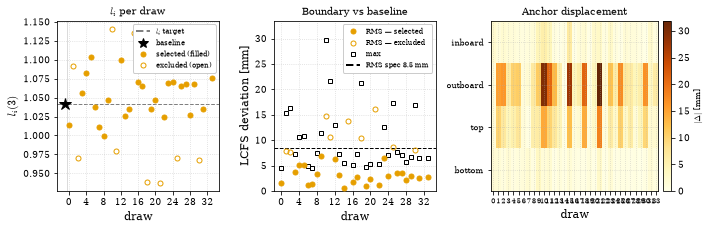

In [11]:
bq.plot_traces(HEADER_L + ".h5", scan_key=0, rms_max_mm=run.boundary_cut()[0]); plt.show()

## 6. Working with the archive

Every run writes a self-contained HDF5 archive: per-draw profiles, separated
currents, scalars, coil currents and the raw g-file bytes of each perturbed
equilibrium. `BouquetArchive` walks it; any draw's g-file can be written out
for an external code.


In [12]:
import tempfile
ar = bq.BouquetArchive(HEADER + ".h5")
sc = ar[ar.scan_keys[0]]
d = sc.selected[0]
eq = d.equilibrium()
print(f"draw {d.count}: l_i(3) = {d.li3:.3f}, Ip = {abs(eq.Ip) / 1e6:.3f} MA, "
      f"q95 = {np.interp(0.95, eq.psi_N, np.abs(eq.qpsi)):.2f}")
print("profiles stored per draw:", sorted(d.profiles)[:8], "...")
out = d.extract(tempfile.mkdtemp(), formats=("geqdsk",))
print("extracted:", {k: os.path.basename(v) for k, v in out.items()})

draw 0: l_i(3) = 0.866, Ip = 1.000 MA, q95 = 4.74
profiles stored per draw: ['T_e', 'T_i', 'aux_zeff', 'coil_currents', 'j_BS', 'j_NBI', 'j_RF', 'j_inductive'] ...
extracted: {'geqdsk': 'synthetic_Hmode_0_0.geqdsk'}


## Error bars

One call per archive slice: `bq.bands_summary` gives, per quantity, the
**median, the 16-84 % band, the full range and n over the in-spec draws**
(the standard recipe of `bouquet.stats`: the population is the draws the
stamped filters select, nothing is filtered on, the baseline is overlaid,
never the centre). The gradients `dp_dpsi` and `djphi_dpsi` are
d/dψ_N of each draw's own archived pressure and j_φ, evaluated on each draw
at **its own q = 2 surface** (located from that draw's archived q profile);
draws without a q = 2 surface are counted and excluded, and if none has one
the helper falls back to ψ_N = 0.5 and says so in the record. Every record
carries the counts at each stage, the dropped draws with their reasons and the
limitations (`summary[q].provenance`).


synthetic_Hmode
Error bars over the in-spec draws of scan '0': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N           0.7865       0.7388       0.8038       0.7297       0.8249    24  
l_i_3            0.8454       0.8025       0.8845       0.7671       0.9291    24  
Lambda            0.855       0.8383       0.8677       0.8275        0.885    24  
dp_dpsi      -2.445e+04   -3.042e+04   -2.121e+04   -3.338e+04   -1.702e+04    24  Pa/psi_N
djphi_dpsi   -1.954e+06   -2.157e+06   -1.579e+06   -2.333e+06   -1.354e+06    24  A m^-2/psi_N



synthetic_Lmode
Error bars over the in-spec draws of scan '0': n = 24  (median, p16-p84 band, full range, n used)
gradients d/dpsi_N at each draw's own q = 2 surface: located on 24 of 24 draws (0 without one, counted and excluded)
quantity         median          p16          p84          min          max     n  unit / flags
beta_N           0.7905       0.7725        0.813       0.7081        0.836    24  
l_i_3             1.052        1.025        1.073       0.9997        1.104    24  
Lambda           0.8784       0.8666       0.8855       0.8406       0.8946    24  
dp_dpsi      -2.673e+04   -2.889e+04   -2.431e+04   -2.973e+04   -2.288e+04    24  Pa/psi_N
djphi_dpsi   -1.673e+06   -1.823e+06    -1.61e+06   -1.968e+06    -1.55e+06    24  A m^-2/psi_N



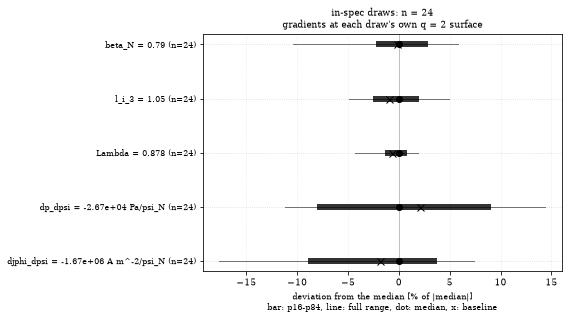

In [13]:
for h in (HEADER, HEADER_L):
    summary = bq.bands_summary(h + ".h5", 0, scalars=("beta_N", "l_i_3", "Lambda"),
                               gradients=("dp_dpsi", "djphi_dpsi"), at={"q": 2.0},
                               fallback_psi_N=0.5)
    print(h); print(summary.table()); print()
summary.plot(); plt.show()      # one band figure (the L-mode case), n stated